In [1]:
import torch

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import json

In [21]:
def draw_plots(path):
    with open(path, "r") as f:
        dic = json.load(f)
    history = dic["history"]
    batch_hist = [row for row in history if "batch_idx" in row]
    epoch_hist = [row for row in history if "batch_idx" not in row]
    bdf = pd.DataFrame(batch_hist)
    edf = pd.DataFrame(epoch_hist)
    # fractional epoch: 2.5 == halfway through epoch 2
    bdf["progress"] = bdf["epoch"] + bdf["batch_percentage"]
    # epoch-level rows are logged at the *end* of the epoch
    edf["progress"] = edf["epoch"] + 1

    train_c, val_c, time_c = "#2a78d6", "#eb6834", "#1baf7a"
    fig, (ax_loss, ax_time, ax_gap,ax_non_smooth) = plt.subplots(
        4, 1, figsize=(16, 16), sharex=True, constrained_layout=True
    )
    fig.suptitle(f"Training run: {path}", fontsize=13)

    # 1) batch loss with epoch-level averages overlaid on the same timeline
    ax_loss.plot(bdf["progress"], bdf["batch_loss"], color=train_c, lw=1,
                 alpha=0.6, label="train loss (per batch)")
    ax_loss.plot(edf["progress"], edf["avg_loss"], color=train_c, lw=2,
                 marker="o", ms=5, label="train loss (epoch avg)")
    ax_loss.plot(edf["progress"], edf["avg_vloss"], color=val_c, lw=2,
                 marker="o", ms=5, label="val loss (epoch avg)")
    ax_loss.set_yscale("log")
    ax_loss.yaxis.set_major_formatter(ScalarFormatter())
    ax_loss.yaxis.set_minor_formatter(ScalarFormatter())
    ax_loss.set_ylabel("cross-entropy loss (log scale)")
    ax_loss.set_title("Loss")
    ax_loss.legend(loc="upper right")

    # 2) per-batch step time
    ax_time.plot(bdf["progress"], bdf["tokens/sec"], color=time_c, lw=1)
    ax_time.set_ylabel("tokens/sec")
    ax_time.set_title("tokens/sec")

    # 3) train/val gap per epoch
    ax_gap.plot(edf["progress"], edf["avg_vloss"] - edf["avg_loss"],
                color=val_c, lw=2, marker="o", ms=5)
    ax_gap.axhline(0, color="0.6", lw=1, ls="--")
    ax_gap.set_ylabel("val loss − train loss")
    ax_gap.set_title("Generalization gap (positive = val worse than train)")
    ax_gap.set_xlabel("epoch")

    # 4) batch non smoothed CE with epoch-level averages overlaid on the same timeline
    if "non_smoothed_loss_fn_val" in edf:
        ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn"], color=train_c, lw=2,
                    marker="o", ms=5, label="train non smoothed CE (epoch avg)")
        ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn_val"], color=val_c, lw=2,
                    marker="o", ms=5, label="val non smoothed CE (epoch avg)")
        ax_non_smooth.set_yscale("log")
        ax_non_smooth.yaxis.set_major_formatter(ScalarFormatter())
        ax_non_smooth.yaxis.set_minor_formatter(ScalarFormatter())
        ax_non_smooth.set_ylabel("cross-entropy loss (log scale)")
        ax_non_smooth.set_title("Non Smoothed Loss")
        ax_non_smooth.legend(loc="upper right")

    for ax in (ax_loss, ax_time, ax_gap,ax_non_smooth):
        ax.grid(True, color="0.9", lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    ax_gap.set_xlim(0, edf["progress"].max())
    ax_gap.set_xticks(range(0, int(edf["progress"].max()) + 1))

    plt.show()
    return bdf, edf, batch_hist

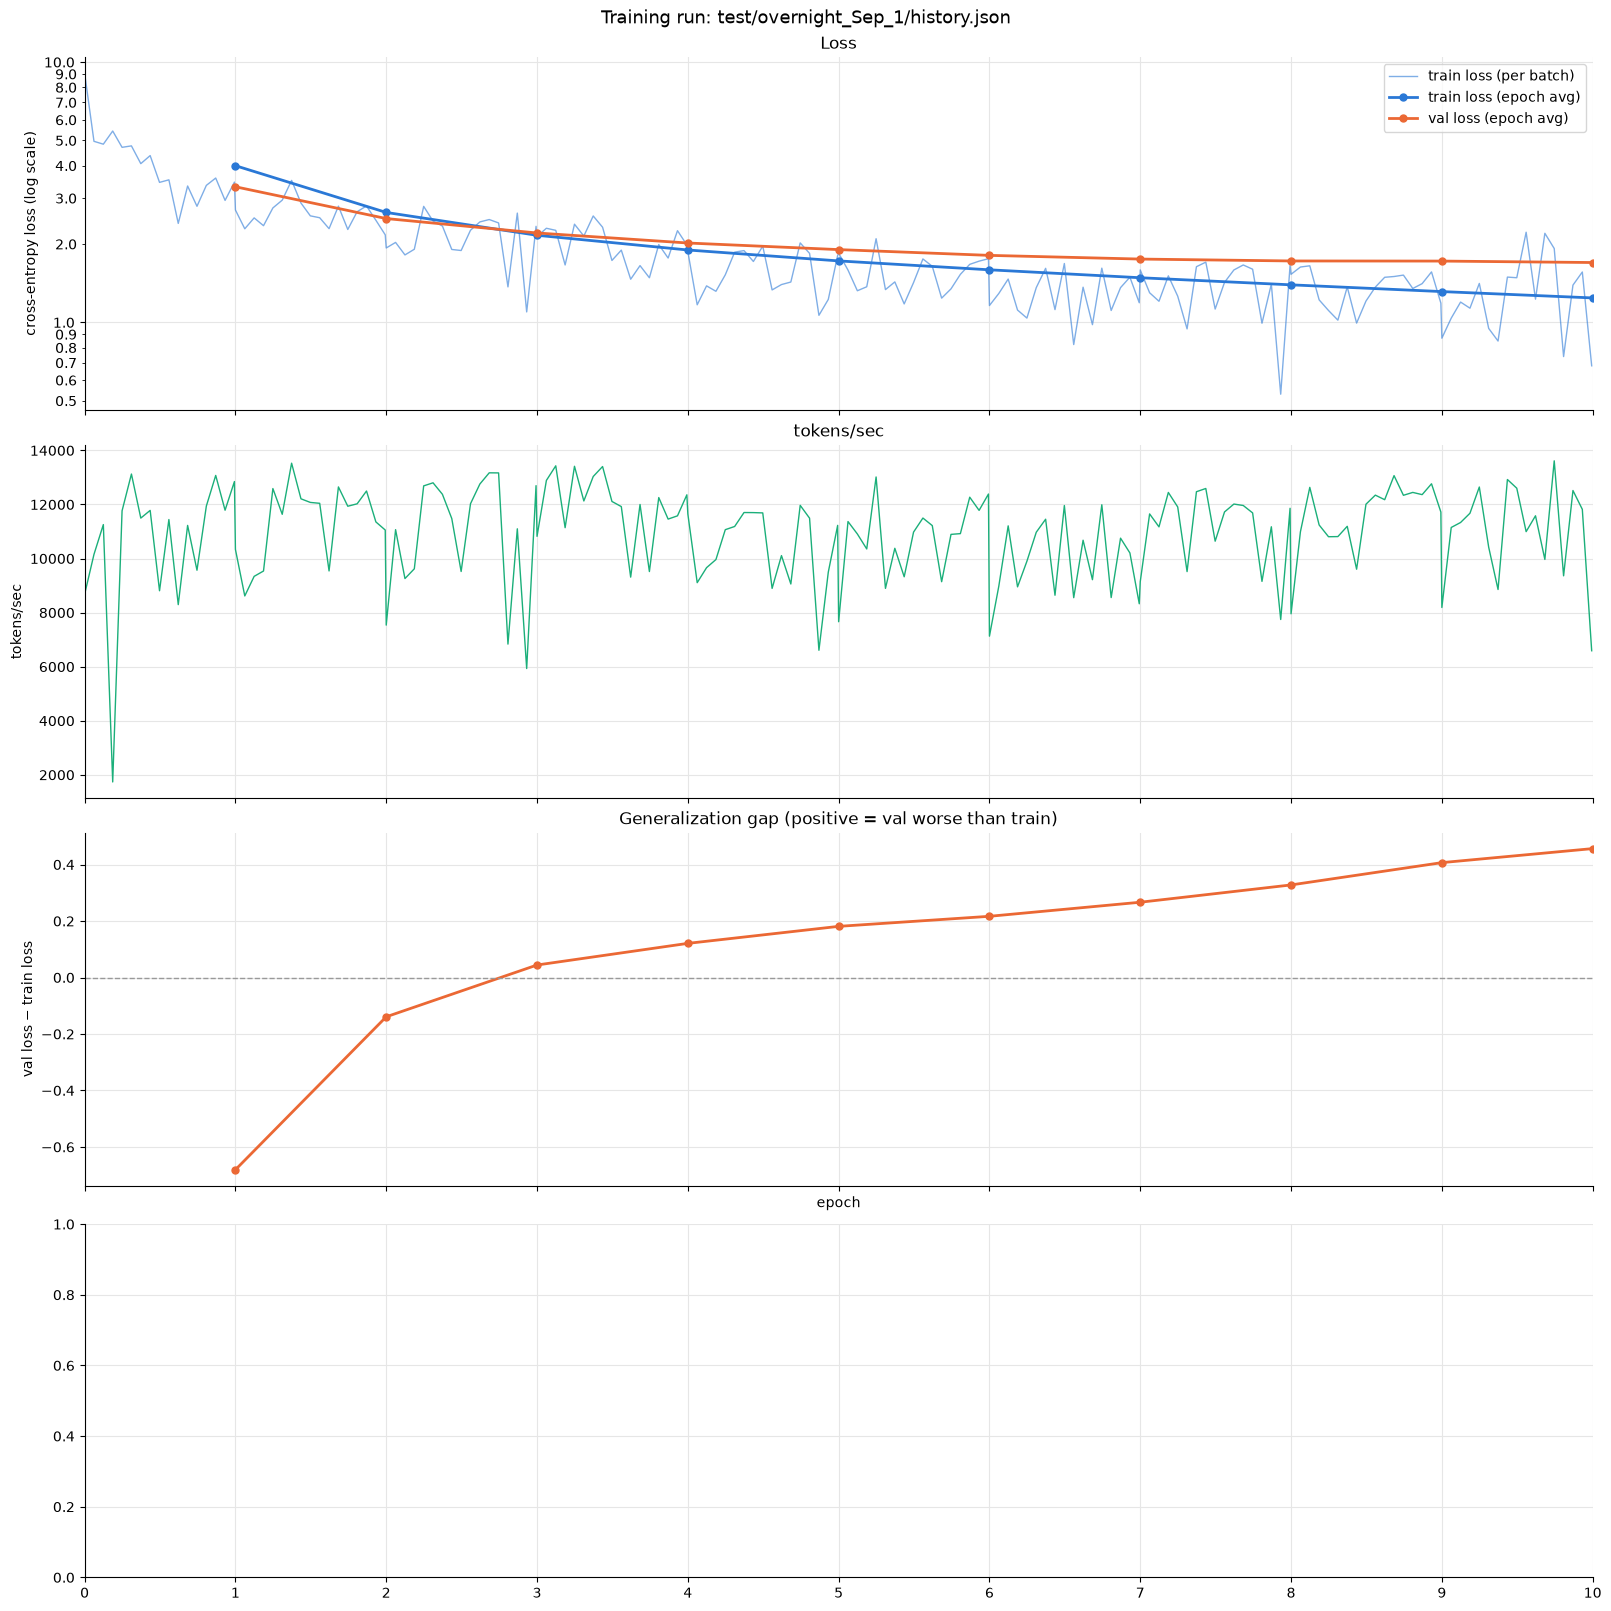

In [20]:
bdf_1,edf_1,batch_hist_1 = draw_plots("test/overnight_Sep_1/history.json")

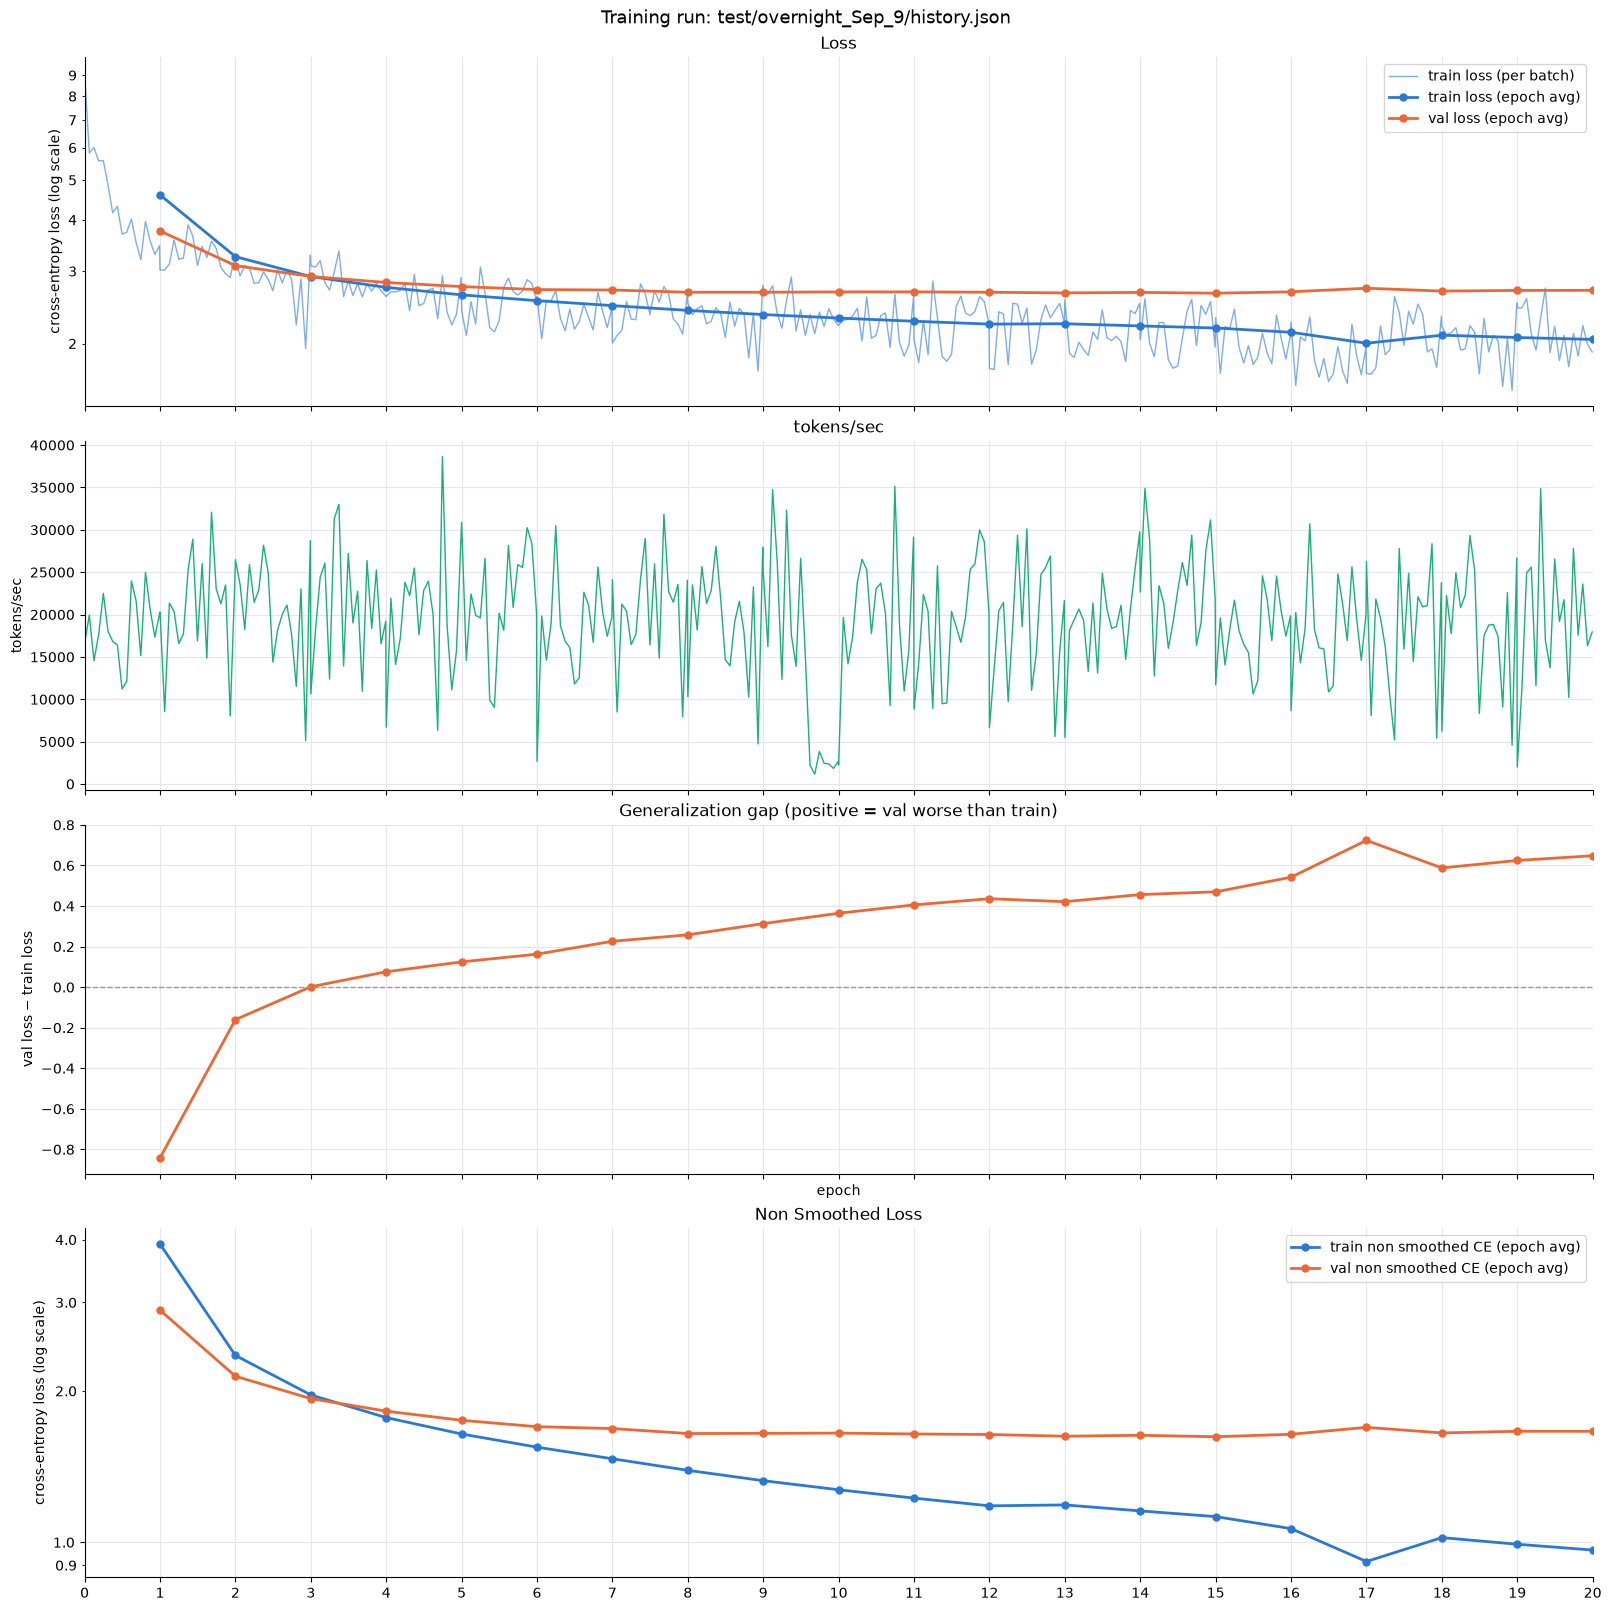

In [86]:
bdf_9,edf_9,batch_hist_9 = draw_plots("test/overnight_Sep_9/history.json")

In [34]:
edf_9.head(15)

,avg_loss,avg_vloss,epoch,avg_time,epoch_time,non_smoothed_loss_fn,non_smoothed_loss_fn_val,progress
0,4.600607,3.758963,0,0.224054,728.235123,3.920981,2.896056,1
1,3.254810,3.094645,1,0.209575,678.188980,2.353563,2.139516,2
2,2.910920,2.912854,2,0.210596,681.275587,1.964267,1.931431,3
3,2.739887,2.815850,3,0.209165,677.109155,1.770508,1.823554,4
4,2.627254,2.751852,4,0.216819,701.441065,1.642390,1.748690,5
5,2.543219,2.705959,5,0.212776,688.588208,1.546178,1.698275,6
6,2.473586,2.699756,6,0.222507,723.793479,1.466149,1.683775,7
7,2.408184,2.666172,7,0.212738,688.601492,1.390481,1.645912,8
8,2.352896,2.666194,8,0.215717,698.024706,1.326126,1.647046,9
9,2.306764,2.671209,9,0.941349,3042.422582,1.272158,1.649126,10


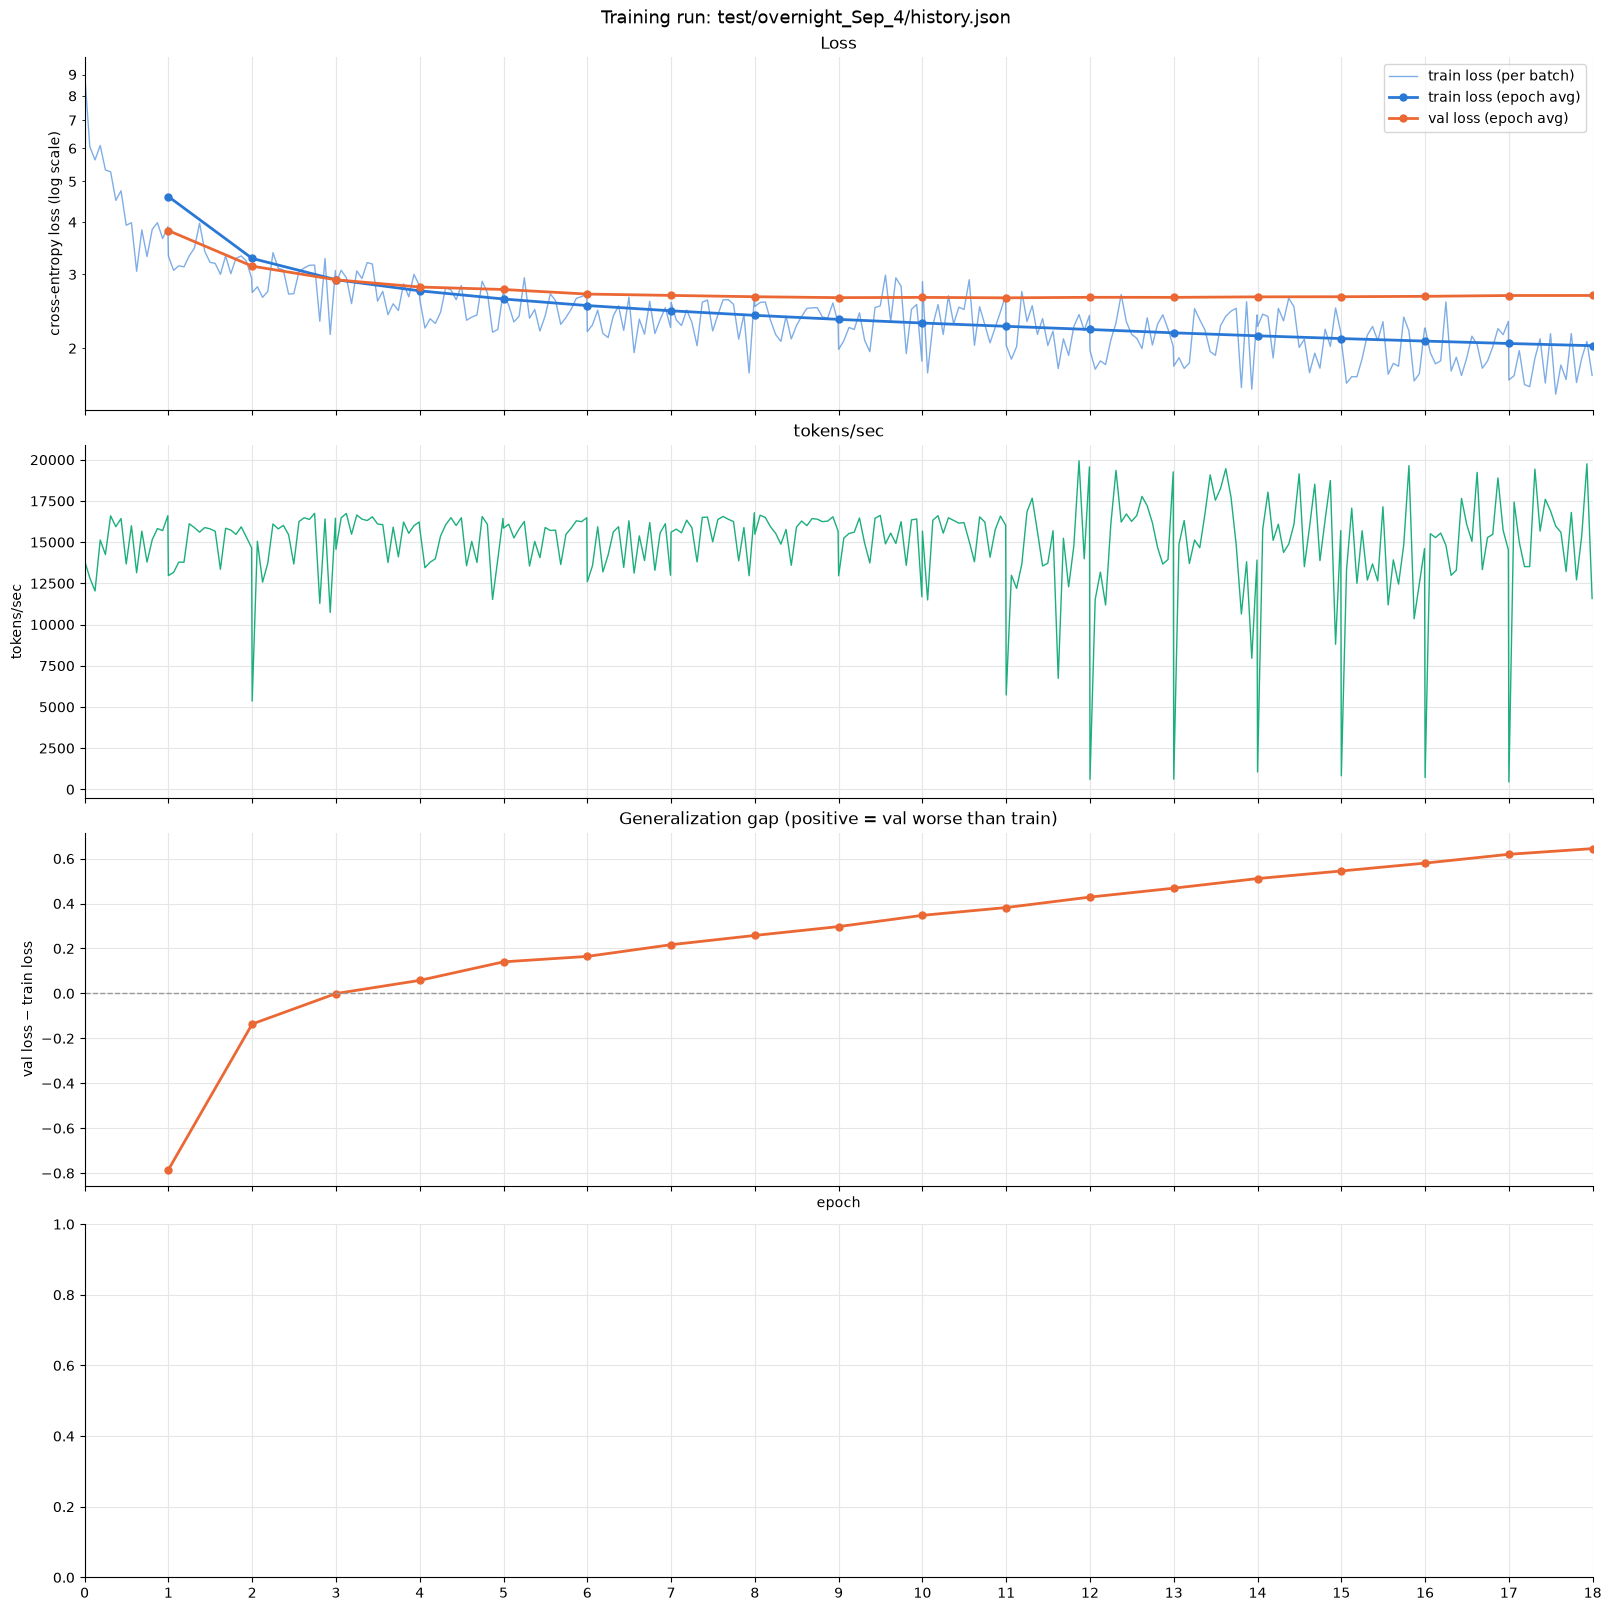

In [35]:
bdf_4,edf_4,batch_hist_4 = draw_plots("test/overnight_Sep_4/history.json")

In [39]:
edf_9.tail()

,avg_loss,avg_vloss,epoch,avg_time,epoch_time,non_smoothed_loss_fn,non_smoothed_loss_fn_val,progress
10,2.266102,2.671711,10,5.687125,18322.971654,1.224391,1.642623,11
11,2.229962,2.666012,11,0.227476,736.717623,1.181746,1.638492,12
12,2.234758,2.656166,12,0.240112,777.003948,1.186867,1.625808,13
13,2.207198,2.663669,13,0.230644,746.697238,1.154674,1.632523,14
14,2.181914,2.651884,14,0.227799,737.663092,1.124939,1.621985,15


In [38]:
edf_4.tail()

,avg_loss,avg_vloss,epoch,avg_time,epoch_time,progress
13,2.141576,2.652772,13,0.311864,1009.196979,14
14,2.109560,2.654568,14,0.331522,1073.104000,15
15,2.080353,2.660345,15,0.314727,1018.333488,16
16,2.053056,2.672292,16,0.316467,1024.179829,17
17,2.028260,2.672870,17,0.322529,1043.856056,18


In [26]:
import sentencepiece
import torch
from torch.distributions import Categorical
from torchmetrics.text import BLEUScore

In [88]:
import importlib
import train
importlib.reload(train)
from train import load_model, DEVICE, AttnDataset, config, collate_fn, load_best_model

In [89]:
model, _, _, loss_fn, metrics, history, _, _, _, _ = load_best_model()



num_parameters: 32,985,088 - num_non_embedding_params: 29,401,088
2026-09-16 16:12:24.771044: optimizer loaded
2026-09-16 16:12:24.773238: scheduler loaded
2026-09-16 16:12:24.773550: loss_fn loaded
2026-09-16 16:12:24.773581: metrics loaded
2026-09-16 16:12:24.773588: loading best pre saved
best model path found.
2026-09-16 16:12:25.630741: Starting from pre saved with: start_epoch: 19, best_val_loss: 2.6519, last_epoch_vloss: 2.69, non_improve_cnt: 2.00


In [90]:
metrics[0].name

'non_smoothed_loss_fn'

In [91]:
sp_bpe = sentencepiece.SentencePieceProcessor()
sp_bpe.load("bpe.model")
metric = BLEUScore()

In [115]:
english_orig_translation = "I like eating carrot."
german_text = "Ich esse gerne Karotten."
german_list_enc = sp_bpe.encode_as_ids(german_text, add_bos=True, add_eos=True)
german_encoding = torch.tensor([german_list_enc]).to(DEVICE)

english_encoding = [sp_bpe.bos_id()]

i = 0
model.eval()
with torch.no_grad():
    while i < 20:
        logits = model.forward(german_encoding,torch.tensor([english_encoding]).to(DEVICE)) # B,Sy,VS
        dist = Categorical(logits=logits[0,-1,:])

        new_enc = dist.sample().item()
        english_encoding.append(new_enc)
        print(f"debug: new encoding: '{sp_bpe.decode_ids(english_encoding)}'")
        if new_enc == sp_bpe.eos_id():
            print("debug: reached EOS")
            break 
        i+=1
score = metric([sp_bpe.decode_ids(english_encoding)], [[english_orig_translation]])
print(f"BLEU Score: {score}")

debug: new encoding: 'So'
debug: new encoding: 'So I'
debug: new encoding: 'So I long'
debug: new encoding: 'So I long like'
debug: new encoding: 'So I long like car'
debug: new encoding: 'So I long like carro'
debug: new encoding: 'So I long like carrots'
debug: new encoding: 'So I long like carrots.'
debug: new encoding: 'So I long like carrots.'
debug: reached EOS
BLEU Score: 0.0


In [83]:
print(english_orig_translation)
print(sp_bpe.decode_ids(english_encoding))

Let's talk about the environment.
Let's talk about the environment.


In [49]:
metric(["Hello this is a cat"], [["Hi this is a dog"]])

tensor(0.)

In [ ]:
# getting val data setup
def encode(item):
    ids = sp_bpe.encode_as_ids(item, add_bos=True)
    return np.array(ids[:128-1]+[sp_bpe.eos_id()], dtype=np.int64)


val_df = pd.read_csv("val_df.csv")

debug: len(val_dt): 888


In [ ]:
totalscore = 0
translation = []
reached_eos = 0
for i,row in val_df.iterrows():
    print(f"debug: at idx: {i}", end=": ")
    
    english_encoding = [sp_bpe.bos_id()]
    x = torch.tensor(encode(row["detext"]), device=DEVICE).reshape((1,-1))
    while i < 120:
        y = torch.tensor([english_encoding],dtype=torch.long, device=DEVICE)
        logits = model(x,y) # B,Sy,VS
        cur_id = torch.argmax(logits,dim=2)[0,-1]
        english_encoding.append(cur_id)
        if cur_id == sp_bpe.eos_id():
            reached_eos+=1
            break
    y_pred = [sp_bpe.decode_ids(english_encoding)]

    y = [[row["entext"]]]
    score = metric(y_pred,y)
    translation.append((y_pred[0],y[0][0],score))
    totalscore+=score
    print(score)

reached_eos/=len(val_df)
totalscore/=len(val_df)

debug: at idx: 0: tensor(0.2638)
debug: at idx: 1: tensor(0.5683)
debug: at idx: 2: tensor(0.2595)
debug: at idx: 3: tensor(0.)
debug: at idx: 4: tensor(0.4581)
debug: at idx: 5: tensor(0.)
debug: at idx: 6: tensor(0.1912)
debug: at idx: 7: tensor(0.2741)
debug: at idx: 8: tensor(0.)
debug: at idx: 9: tensor(0.2361)
debug: at idx: 10: tensor(0.2447)
debug: at idx: 11: tensor(0.)
debug: at idx: 12: tensor(0.2031)
debug: at idx: 13: tensor(0.)
debug: at idx: 14: tensor(0.)
debug: at idx: 15: tensor(0.)
debug: at idx: 16: tensor(0.)
debug: at idx: 17: tensor(0.)
debug: at idx: 18: tensor(0.2535)
debug: at idx: 19: tensor(0.)
debug: at idx: 20: tensor(0.5129)
debug: at idx: 21: tensor(0.)
debug: at idx: 22: tensor(0.)
debug: at idx: 23: tensor(0.)
debug: at idx: 24: tensor(0.2989)
debug: at idx: 25: tensor(0.7703)
debug: at idx: 26: tensor(0.4948)
debug: at idx: 27: tensor(0.)
debug: at idx: 28: tensor(0.)
debug: at idx: 29: tensor(0.)
debug: at idx: 30: tensor(0.)
debug: at idx: 31: tenso

KeyboardInterrupt: 

In [149]:
translation[0]

('Last year, I showed these two slides to illustrate that the Arctic ice cap, which has been the size of the bottom 48 states, 40 percent shrinking.',
 'Last year I showed these two slides so that  demonstrate that the arctic ice cap,  which for most of the last three million years  has been the size of the lower 48 states,  has shrunk by 40 percent.',
 tensor(0.2638))

In [38]:
from train import load_data, lr_update_fn
import torch

In [39]:
config["mega_batch_size"]

50

In [40]:
train_loader, val_loader = load_data()

2026-09-09 02:11:08.210538: # train sentences 206,112
2026-09-09 02:11:08.210672: # train docs 1,705
2026-09-09 02:11:08.210682: # val sentences 888
   Unnamed: 0 index  docid  segid  \
0           0   1,1      1      1   
1           1   1,2      1      2   
2           2   1,3      1      3   
3           3   1,4      1      4   
4           4   1,5      1      5   

                                              entext  \
0                          Thank you so much, Chris.   
1  And it's truly a great honor to have the oppor...   
2  I have been blown away by this conference, and...   
3  And I say that sincerely, partly because  I ne...   
4                     Put yourselves in my position.   

                                              detext  
0                                Vielen Dank, Chris.  
1  Es ist mir wirklich eine Ehre, zweimal auf die...  
2  Ich bin wirklich begeistert von dieser Konfere...  
3  Das meine ich ernst, teilweise deshalb -- weil...  
4              V

In [41]:
total_x = 0
total_y = 0
x_len=0
y_len=0

pad_tokens = 0
for X,Y in train_loader: # B,Sy
    cur_x = torch.sum(X != config["pad_token"])
    cur_y = torch.sum(Y != config["pad_token"])
    pad_tokens += X.shape[0] * (X.shape[1] + Y.shape[1]) - cur_x - cur_y
    total_x+=cur_x
    total_y+=cur_y

    x_len+=X.shape[1]
    y_len+=Y.shape[1]

In [ ]:
print(f"total_x: {total_x.item():,}")
print(f"total_y: {total_y.item():,}")
print(f"total_pad_tokens: {pad_tokens.item():,}")

print("per step: ")
print(f"total_x: {total_x / len(train_loader):,.2f}")
print(f"total_y: {total_y / len(train_loader):,.2f}")
print(f"pad_tokens: {pad_tokens / len(train_loader) / 2:,.2f}")
print(f"X_len: {x_len / len(train_loader):.2f}")
print(f"Y_len: {y_len / len(train_loader):.2f}")

total_x: 5,838,142
total_y: 5,697,404
pad_tokens: 2,860,038
per step: 
total_x: 1,812.52
total_y: 1,768.83
pad_tokens: 443.97
X_len: 29.72
Y_len: 40.15


In [47]:
batches_per_epoch_me = 3221 # from logs/output_logs_overnight_Sep_5_2.txt
num_epochs_me = 10
sent_len_me = (x_len + y_len)/(2*len(train_loader))
sent_len_them = sent_len_me #??
print(f"tokens seen total: {100_000 * 25_000:,} - {(total_x) * num_epochs_me:,}")
print(f"tokens/batch:      {25_000:,} - {(total_x + total_y)/len(train_loader):,.0f}")
print(f"tokens/epoch:      {4_500_000 * sent_len_them:,.0f} - {total_x + total_y:,}") # assuming they have the same sentence length as us
print(f"batches/epoch:     {(4_500_000 * sent_len_them / 25_000):,.0f} - {batches_per_epoch_me:,}") # batches_t * tokens/epoch / tokens_t
print(f"epochs:            {100_000 / ((4_500_000 * sent_len_them / 25_000)):.1f} - {num_epochs_me}")
print(f"batches:           {100_000:,} - {batches_per_epoch_me * num_epochs_me:,.2f}")

tokens seen total: 2,500,000,000 - 58,381,420
tokens/batch:      25,000 - 3,581
tokens/epoch:      157,206,613 - 11,535,546
batches/epoch:     6,288 - 3,221
epochs:            15.9 - 10
batches:           100,000 - 32,210.00


took back: 

- higher tokens/batch than paper -> less gradient noise. Hence better. 
- batches/epoch is half -> Noam LR is still warming up at the start
- total batches is third -> Noam LR is not fully calmed down yet at the end -> lower warmup_steps. 
- 

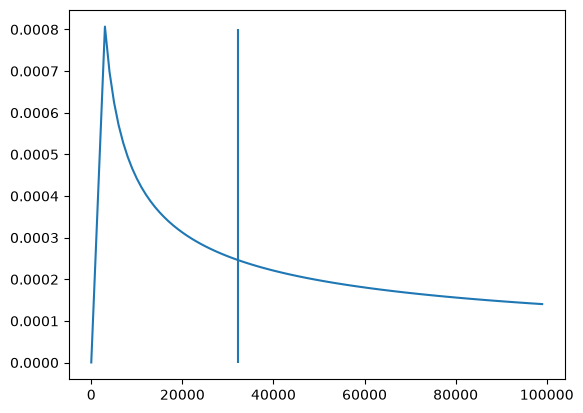

In [80]:
plt.plot([i for i in range(0,100_000,1_000)],[lr_update_fn(i) for i in range(0,100_000,1_000)])
plt.vlines(32_210,ymin=0,ymax=0.0008)

In [48]:
import torch
d = torch.nn.Dropout(0.1).train()
x = torch.ones(1, 8, 512)          # B, S, d_model
out = d(x)
print((out == 0).float().mean())    # fraction of individual numbers zeroed
print((out == 0).all(dim=-1).sum()) # how many whole tokens zeroed


tensor(0.1008)
tensor(0)
